In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix , f1_score
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder
from sklearn.compose import make_column_transformer, make_column_selector
import warnings
warnings.filterwarnings('ignore')
from sklearn import set_config
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.neighbors import KNeighborsRegressor
from sklearn.datasets import make_regression
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_regression, RFECV, SelectFromModel
from sklearn.metrics import mean_squared_error, mean_squared_log_error, mean_absolute_error, r2_score

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier


## Análise exploratória dos dados

A base de dados fornecida esta dividida em vinhos brancos e vinhos tintos entao para essa analize transformei essa diferenca em variavel concatenei as duas bases e acresentei uma nova coluna 'tipo' que mostra o tipo do vinho

In [2]:
vinhos_branco = pd.read_excel('Qualidade_Vinho.xlsx',sheet_name='Qualidade_Vinho_Branco')
vinhos_tinto = pd.read_excel('Qualidade_Vinho.xlsx',sheet_name='Qualidade_Vinho_Tinto')

vinhos_branco['tipo'] = 'branco'
vinhos_tinto['tipo'] = 'tinto'

vinhos = pd.concat([vinhos_branco,vinhos_tinto], ignore_index=True)

print(vinhos.head(5))
print(vinhos.tail(5))

   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.0              0.27         0.36            20.7      0.045   
1            6.3              0.30         0.34             1.6      0.049   
2            8.1              0.28         0.40             6.9      0.050   
3            7.2              0.23         0.32             8.5      0.058   
4            7.2              0.23         0.32             8.5      0.058   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 45.0                 170.0   1.0010  3.00       0.45   
1                 14.0                 132.0   0.9940  3.30       0.49   
2                 30.0                  97.0   0.9951  3.26       0.44   
3                 47.0                 186.0   0.9956  3.19       0.40   
4                 47.0                 186.0   0.9956  3.19       0.40   

   alcohol  quality    tipo  
0      8.8      6.0  branco  
1      9.5      6.0  branc

In [3]:
vinhos.info()

<class 'pandas.DataFrame'>
RangeIndex: 6586 entries, 0 to 6585
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6580 non-null   float64
 1   volatile acidity      6571 non-null   float64
 2   citric acid           6552 non-null   float64
 3   residual sugar        6554 non-null   float64
 4   chlorides             6546 non-null   float64
 5   free sulfur dioxide   6547 non-null   float64
 6   total sulfur dioxide  6546 non-null   float64
 7   density               6550 non-null   float64
 8   pH                    6543 non-null   float64
 9   sulphates             6538 non-null   float64
 10  alcohol               6549 non-null   float64
 11  quality               6577 non-null   float64
 12  tipo                  6586 non-null   str    
dtypes: float64(12), str(1)
memory usage: 669.0 KB


checagem de quantas linhas sao duplicadas 

In [4]:
vinhos.duplicated().sum()

np.int64(1241)

drop das linhas duplicadas 

In [5]:
vinhos_desdup = vinhos.drop_duplicates()
vinhos_desdup.info()

<class 'pandas.DataFrame'>
Index: 5345 entries, 0 to 6571
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         5340 non-null   float64
 1   volatile acidity      5332 non-null   float64
 2   citric acid           5330 non-null   float64
 3   residual sugar        5332 non-null   float64
 4   chlorides             5330 non-null   float64
 5   free sulfur dioxide   5329 non-null   float64
 6   total sulfur dioxide  5329 non-null   float64
 7   density               5331 non-null   float64
 8   pH                    5326 non-null   float64
 9   sulphates             5323 non-null   float64
 10  alcohol               5327 non-null   float64
 11  quality               5342 non-null   float64
 12  tipo                  5345 non-null   str    
dtypes: float64(12), str(1)
memory usage: 584.6 KB


checagem de quantas linhas tem valores vazios 

In [6]:
vinhos_desdup.isna().sum()

fixed acidity            5
volatile acidity        13
citric acid             15
residual sugar          13
chlorides               15
free sulfur dioxide     16
total sulfur dioxide    16
density                 14
pH                      19
sulphates               22
alcohol                 18
quality                  3
tipo                     0
dtype: int64

drop das linhas com espacos vazios 
ha uma quantidade muito pequena de elementos vazios por coluna entao eu nao acho nessessario imputar valores para eles
eles podem ser descartados sem causar problemas para a analise estatistica 

In [7]:
vinhos_sem_na = vinhos_desdup.dropna()
vinhos_sem_na.info()

<class 'pandas.DataFrame'>
Index: 5320 entries, 0 to 6571
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         5320 non-null   float64
 1   volatile acidity      5320 non-null   float64
 2   citric acid           5320 non-null   float64
 3   residual sugar        5320 non-null   float64
 4   chlorides             5320 non-null   float64
 5   free sulfur dioxide   5320 non-null   float64
 6   total sulfur dioxide  5320 non-null   float64
 7   density               5320 non-null   float64
 8   pH                    5320 non-null   float64
 9   sulphates             5320 non-null   float64
 10  alcohol               5320 non-null   float64
 11  quality               5320 non-null   float64
 12  tipo                  5320 non-null   str    
dtypes: float64(12), str(1)
memory usage: 581.9 KB


estatistica descritiva das variaveis numericas 
podemos ver que as variaveis: 
- 'residual sugar' tem a media e mediana distantes oque apresenta distribuicao nao normal
- 'free sulfur dioxide' 'total sulfur dioxide' tem medias e medianas delocadas oque tambem mostra uma distibuicao nao normal
- 'fixed acidity' 'volatile acidity' 'citric acid' 'residual sugar' 'free sulfur dioxide' 'total sulfur dioxide' 'sulphates' 'alcohol' tem outliers que podem interfirir na analise 


In [8]:
vinhos_sem_na.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,5320.000000,5320.000000,5320.000000,5320.000000,5320.000000,5320.000000,5320.000000,5320.000000,5320.000000,5320.000000,5320.000000,5320.000000
mean,7.215179,0.344130,0.318494,5.048477,0.056690,30.036654,114.109023,0.994535,3.224664,0.533357,10.549241,5.795677
std,1.319671,0.168248,0.147157,4.500180,0.036863,17.805045,56.774223,0.002966,0.160379,0.149743,1.185933,0.879772
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.400000,0.230000,0.240000,1.800000,0.038000,16.000000,74.000000,0.992200,3.110000,0.430000,9.500000,5.000000
50%,7.000000,0.300000,0.310000,2.700000,0.047000,28.000000,116.000000,0.994650,3.210000,0.510000,10.400000,6.000000
75%,7.700000,0.410000,0.400000,7.500000,0.066000,41.000000,153.250000,0.996770,3.330000,0.600000,11.400000,6.000000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000,9.000000


In [9]:
vinhos_sem_na.describe(include='O')

,tipo
count,5320
unique,2
top,branco
freq,3961


matris de corelacao das varaiveis 
as variaveis 'total sulfur dioxide' e 'free sulfur dioxide' tem corelacao positiva de 72% que é  de se esperara ja que as duas medem a consentracao e dioxido de enchofre no vinho 
as variaveis 'density' e 'alcohol' tem corelacao negativa de 67% deve ter uma esplicacao quimica para isso mas eu desconhesso 

analisando os graficos apenas a variavel 'ph' tem uma distibuicao claramente normal

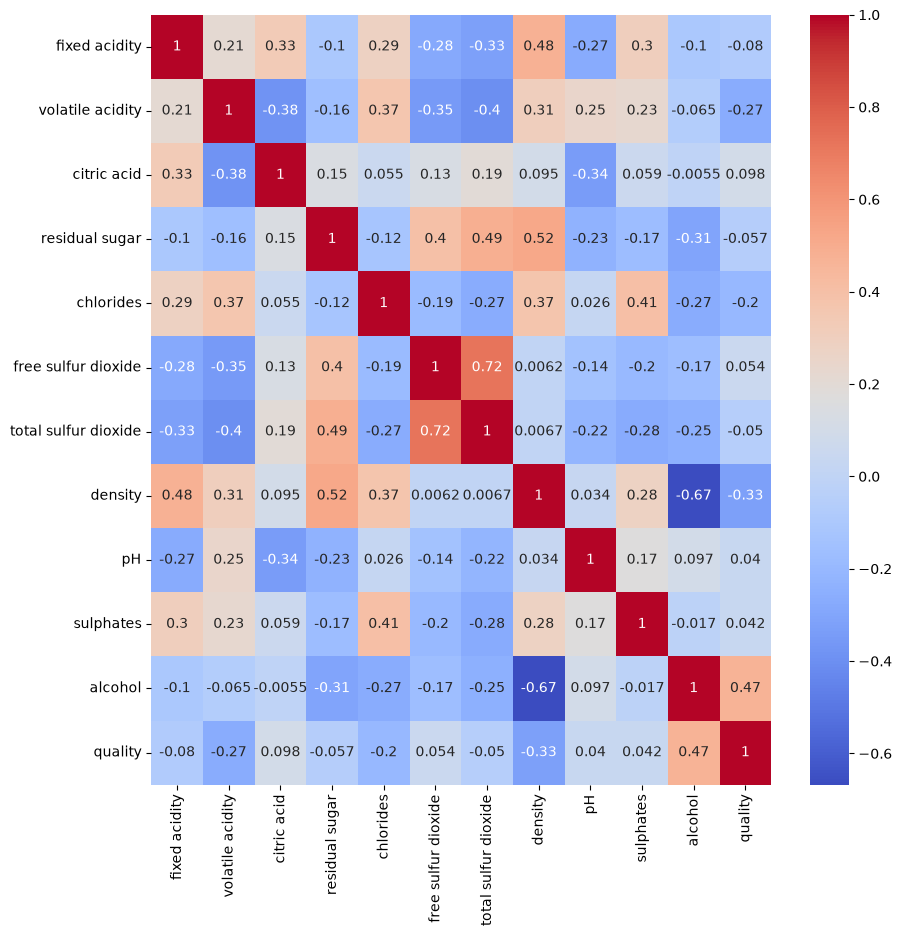

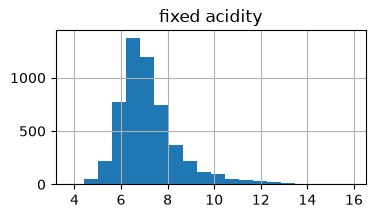

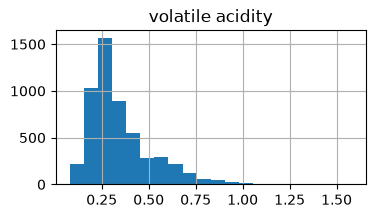

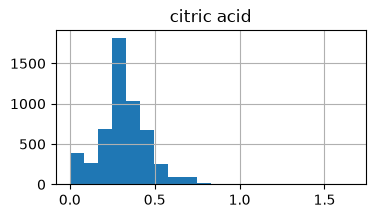

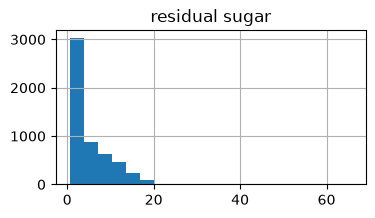

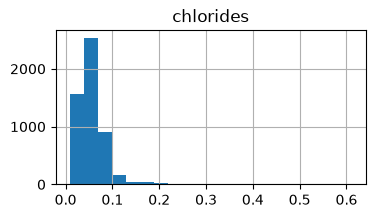

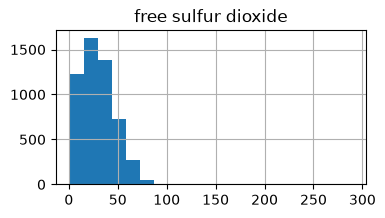

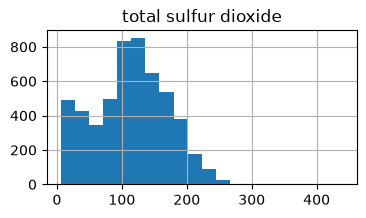

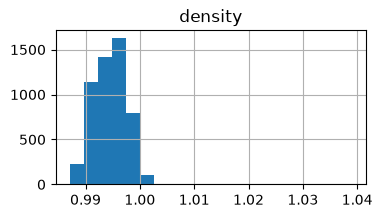

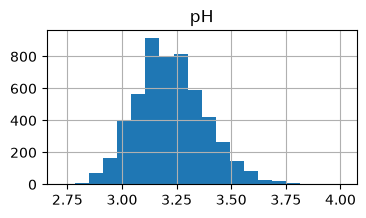

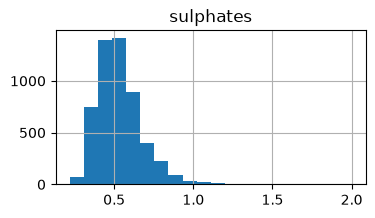

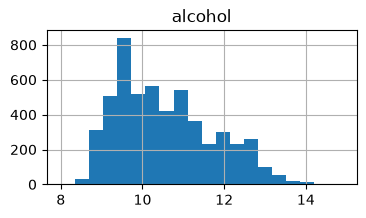

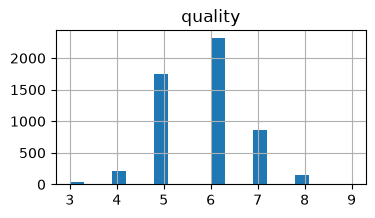

In [10]:
# Análise de Correlação para variáveis numéricas
# Calcula a correlação entre as variáveis numéricas.
correlation_matrix = vinhos_sem_na.select_dtypes(
   include=['int64', 'float64']
).corr()
plt.figure(figsize=(10, 10))
# Exibe a matriz de correlação em um mapa de calor.
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.show()


# Criação de histogramas para todas as variáveis numéricas
# Seleciona apenas as colunas numéricas.
numerical_columns = vinhos_sem_na.select_dtypes(
    include=['int64', 'float64']
).columns

# Cria um histograma para cada variável numérica.
for column in numerical_columns:
    plt.figure(figsize=(4, 2))
    vinhos_sem_na[column].hist(bins=20)
    plt.title(column)
    plt.show()

divisao de treino e teste com regra de 80/20

In [ ]:
x = vinhos_sem_na
y = x.pop("quality")

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

graficos das variaveis de x_treino seguem os mesmos padroes da ultima analise 

In [ ]:
# Análise de Correlação para variáveis numéricas
# Calcula a correlação entre as variáveis numéricas.
correlation_matrix = x_train.select_dtypes(
   include=['int64', 'float64']
).corr()
plt.figure(figsize=(10, 10))
# Exibe a matriz de correlação em um mapa de calor.
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.show()


# Criação de histogramas para todas as variáveis numéricas
# Seleciona apenas as colunas numéricas.
numerical_columns = x_train.select_dtypes(
    include=['int64', 'float64']
).columns

# Cria um histograma para cada variável numérica.
for column in numerical_columns:
    plt.figure(figsize=(4, 2))
    x_train[column].hist(bins=20)
    plt.title(column)
    plt.show()

pipeline de preprocessamento 
por causa da presensa de outliers e da distribuicao nao normal das variaveis escolhi usa robustscaler para padronizar os valores numericos 
e para a variavel tipo a unica variavel categorica foi usado onehotencoder 

In [ ]:
CATEGORICOS = ['tipo']

NUMERICAS = ["fixed acidity",
            "volatile acidity",
            "citric acid",
            "residual sugar",
            "chlorides",
            "free sulfur dioxide",
            "total sulfur dioxide",
            "density",
            "pH",
            "sulphates",
            "alcohol"]

numeric_pipe = make_pipeline(RobustScaler())

categoric_pipe = make_pipeline(OneHotEncoder(sparse_output=False, handle_unknown="ignore"))

preprocessor = ColumnTransformer(
    transformers=[
        ("num_pipe",numeric_pipe,NUMERICAS),
        ("cat_pipe",categoric_pipe,CATEGORICOS)
    ]
)

pipe line para ramdom forest 

In [ ]:
pipeline_RandomForestRegressor = make_pipeline(preprocessor, RandomForestRegressor())

# Define os parâmetros que serão testados pelo GridSearchCV
param_grid_random_forest = {
    "randomforestregressor__n_estimators": [100, 200],
    "randomforestregressor__max_depth": [None, 5, 10, 15],
    "randomforestregressor__min_samples_split": [2, 3, 5],
    "randomforestregressor__min_samples_leaf": [2, 5, 7]
}

# Reduzir o número de dobras (folds( para a validação cruzada
cv = 5

# Cria a busca pelos melhores parâmetros (Grid Search)
search_RF = GridSearchCV(pipeline_RandomForestRegressor,
                         param_grid_random_forest,
                         cv=cv,
                         verbose=1,
                         error_score='raise')
# Fit 
search_RF.fit(x_train, y_train)

pipeline para ridge 
usei ridge para a anlise porque memo tendo variaveis que calculao coisas parecidas ha poucas vaiaveis presentes na base entao usar lasso e retir uma pode comprometer a confianca no modelo

In [ ]:
pipeline_ridge = make_pipeline(preprocessor, Ridge())

param_grid_ridge = {

    # Alpha controla a intensidade da penalização dos coeficientes.
    # Valores maiores = penalização mais forte.
    # Valores menores = penalização mais fraca.
    "ridge__alpha": [0.1, 1, 10],

    # Define se o modelo deve calcular o intercepto.
    # True = calcula o intercepto.
    # False = não calcula o intercepto.
    "ridge__fit_intercept": [True, False]
}


# Cria o Grid Search para testar todas as combinações dos hiperparâmetros definidos acima.
search_ridge = GridSearchCV(
    
    pipeline_ridge,  # Pipeline completo: pré-processamento + Ridge
    
    param_grid_ridge,     # Hiperparâmetros e valores que serão testados
    
    cv=5,                  # Validação cruzada em 5 partes (5-fold)
    
    verbose=1              # Exibe informações durante a execução
)


# Treina o Grid Search com os dados de treinamento.
# Testa as combinações, realiza a validação cruzada e identifica a melhor configuração da Ridge.
search_ridge.fit(x_train, y_train)

pipeline KNN 
utilisei esse modelo porque ele em sua essencia agupa visinhos prossimos e eu tenho como hipotese que vinhos de notas parecidas tem caracteristicas quimicas tambem parecidas como é muito falado que vinhos tintos sao "secos" e densos e vinhos brancos sao suaves e "leves" 

In [ ]:
pipeline_KNeighborsRegressor = make_pipeline(preprocessor, KNeighborsRegressor())

# Define as combinações de hiperparâmetros que serão testadas
param_grid_knn = {
    # Número de vizinhos utilizados para realizar a previsão:
    "kneighborsregressor__n_neighbors": range(2, 20),

    # Define o peso dos vizinhos: uniform = mesmo peso | distance = maior peso para os mais próximos
    "kneighborsregressor__weights": ['uniform', 'distance'],

    # Algoritmo utilizado para encontrar os vizinhos mais próximos
    "kneighborsregressor__algorithm": [
        'auto',       # escolhe automaticamente
        'ball_tree',  # utiliza Ball Tree
        'kd_tree',    # utiliza KD Tree
        'brute'       # calcula diretamente as distâncias
    ]
}


# Cria o Grid Search para testar as combinações de hiperparâmetros
search_knn = GridSearchCV(
    pipeline_KNeighborsRegressor,  # Pipeline completo: pré-processamento + KNN
    param_grid_knn,     # Hiperparâmetros e valores a serem testados
    cv=5,                # Validação cruzada em 5 partes (5-fold)
    verbose=1,           # Exibe informações sobre o processo
    error_score='raise'  # Interrompe se ocorrer algum erro
)


# Treina o Grid Search nos dados de treinamento
# Testa as combinações, realiza a validação cruzada e identifica a melhor configuração do KNN
search_knn.fit(x_train, y_train)

In [ ]:
predict_RF = search_RF.predict(x_test)
predict_ridge = search_ridge.predict(x_test)
predict_knn = search_knn.predict(x_test)

R2 para os modelos selecionados pelo grid search 

In [ ]:
RF_r2 = r2_score(y_test, predict_RF)
ridge_r2 = r2_score(y_test, predict_ridge)
knn_r2 = r2_score(y_test, predict_knn)

# DataFrame for performances
performances = pd.DataFrame({
    'random_forest': RF_r2,
    'ridge': ridge_r2,
    'knn': knn_r2
}, index=['grid search'])


calculo dos erros para avaliacao dos modelos

In [ ]:
#Root mean squared error score 
rmse_score_RF = mean_squared_log_error(y_test, predict_RF)
print("Random Forest Mean Square Log Error (MSLE):", rmse_score_RF)

# Mean Square Error (MSE)
mse_score_RF = mean_squared_error(y_test, predict_RF)
print("Random Forest Mean Square Error (MSE):", mse_score_RF)

# Mean Absolute Error (MAE)
mae_score_RF = mean_absolute_error(y_test, predict_RF)
print("Random Forest Mean Absolute Error (MAE):", mae_score_RF)

# Root mean squared log error score 
rmse_score_ridge = mean_squared_log_error(y_test, predict_ridge)
print("Ridge Mean Square Log Error (MSLE):", rmse_score_ridge)

# Mean Square Error (MSE)
mse_score_ridge = mean_squared_error(y_test, predict_ridge)
print("Ridge Mean Square Error (MSE):", mse_score_ridge)

# Mean Absolute Error (MAE)
mae_score_ridge = mean_absolute_error(y_test, predict_ridge)
print("Ridge Mean Absolute Error (MAE):", mae_score_ridge)

#Root mean squared log error score 
rmse_score_knn = mean_squared_log_error(y_test, predict_knn)
print("KNN Mean Square Log Error (MSLE):", rmse_score_knn)

# Mean Square Error (MSE)
mse_score_knn = mean_squared_error(y_test, predict_knn)
print("KNN Mean Square Error (MSE):", mse_score_knn)

# Mean Absolute Error (MAE)
mae_score_knn = mean_absolute_error(y_test, predict_knn)
print("KNN Mean Absolute Error (MAE):", mae_score_knn)

# DataFrame for performances
error = pd.DataFrame({
    'random_forest': [rmse_score_RF,mse_score_RF,mae_score_RF],
    'ridge': [rmse_score_ridge,mse_score_ridge,mae_score_ridge],
    'knn': [rmse_score_knn,mse_score_knn,mae_score_knn]
}, index=['mean_squared_log_error','mean_squared_error','mean_absolute_error'])

avaliador por minmax scaler 

In [ ]:
pipeline = make_pipeline(preprocessor, MinMaxScaler()).set_output(transform='pandas')

#Use the pipeline created above to fit and transform the train data 
x_train_trans_fit = pipeline.fit_transform(x_train, y_train)

#Transform the test set
x_test_trans_fit = pipeline.transform(x_test)

rf_reg = RandomForestRegressor()
rf_reg.fit(x_train_trans_fit, y_train)

ridge_reg = Ridge()
ridge_reg.fit(x_train_trans_fit, y_train)

treeknn = KNeighborsRegressor(n_neighbors=3)
treeknn.fit(x_train_trans_fit, y_train)

# Predict the new data 

predict_MM_RF = rf_reg.predict(x_test_trans_fit)
predict_MM_ridge = ridge_reg.predict(x_test_trans_fit)
predict_MM_knn = treeknn.predict(x_test_trans_fit)

# R squared
RF_r2 = r2_score(y_test, predict_MM_RF)
ridge_r2 = r2_score(y_test, predict_MM_ridge)
knn_r2 = r2_score(y_test, predict_MM_knn)


# DataFrame for performances
performances.loc['transformed_MaxMin', "random_forest"] = RF_r2
performances.loc['transformed_MaxMin', "ridge"] = ridge_r2
performances.loc['transformed_MaxMin', "knn"] = knn_r2

performances

avaliador por variance threshold 

In [ ]:
range_var_df = (pd.DataFrame({
                'Range': x_train_trans_fit.max() - x_train_trans_fit.min(),
                'Variance': x_train_trans_fit.var()})
                .sort_values(by='Variance'))

selector = VarianceThreshold(threshold=0.002)

x_train_var = selector.fit_transform(x_train_trans_fit)

# Apply the variance threshold to the scaled test set
x_test_var = selector.transform(x_test_trans_fit)

# Random Forest Regression
random_forest_reg = RandomForestRegressor()
random_forest_reg.fit(x_train_var, y_train)
random_forest_reg_pred = random_forest_reg.predict(x_test_var)

# Ridge
ridge_reg = Ridge()
ridge_reg.fit(x_train_var, y_train)
ridge_reg_pred = ridge_reg.predict(x_test_var)

# K-Nearest Neighbors
var_knn = KNeighborsRegressor(n_neighbors=1)
var_knn.fit(x_train_var, y_train)
var_knn_pred = var_knn.predict(x_test_var)

# Inicialize o DataFrame de performances
performances.loc["varThreshold_002", "random_forest"] = r2_score(y_test, random_forest_reg_pred)
performances.loc["varThreshold_002", "ridge"] = r2_score(y_test, ridge_reg_pred)
performances.loc["varThreshold_002", "knn"] = r2_score(y_test, var_knn_pred)

performances

avaliador por k-best 

In [ ]:
# Creando a pipeline e iniciando KBest, udando f-regression e k=10.
pipeline_kbest = make_pipeline(preprocessor,
                               MinMaxScaler(),
                               SelectKBest(score_func=f_regression, k=10)).set_output(transform='pandas') 

# Utilize o pipeline criado acima para ajustar e transformar os dados de treino
x_train_kbest = pipeline_kbest.fit_transform(x_train, y_train)

# Transforme o conjunto de teste
x_test_kbest = pipeline_kbest.transform(x_test)

# Random Forest Regression
random_forest_reg = RandomForestRegressor()
random_forest_reg.fit(x_train_kbest, y_train)
random_forest_reg_pred = random_forest_reg.predict(x_test_kbest)

# Ridge
ridge_reg = Ridge()
ridge_reg.fit(x_train_kbest, y_train)
ridge_reg_pred = ridge_reg.predict(x_test_kbest)

#Store the K-Nearest Neighbor
neigh = KNeighborsRegressor(n_neighbors=12)
neigh.fit(x_train_kbest, y_train)
knn_pred_kbest = neigh.predict(X = x_test_kbest)


# Para armazenar o R² de cada modelo após a seleção das 10 melhores variáveis pelo K-Best, 
# e exibir uma tabela performances permite comparar o desempenho dos modelos usando K-Best.
    

performances.loc["KBest_10", "random_forest"] = r2_score(y_test, random_forest_reg_pred)
performances.loc["KBest_10", "ridge"] = r2_score(y_test, ridge_reg_pred)
performances.loc["KBest_10", "knn"] = r2_score(y_test, knn_pred_kbest)

performances

avaliador por RFE para random forest e ridge o KNN nao tem avaliador por RFE

In [ ]:
# Criando um pipeline com MinMaxScaler e RFECV para Random Forest Regressor
pipeline_rfe_forest = make_pipeline(preprocessor,
MinMaxScaler(),
RFECV(RandomForestRegressor()).set_output(transform='pandas'))

# Ajustar e transformar os dados de treino com o pipeline para RFE com Forest Regressor
x_train_rfe_forest = pipeline_rfe_forest.fit_transform(x_train, y_train)
x_test_rfe_forest = pipeline_rfe_forest.transform(x_test)

# Inicializar modelos para Regressão Linear, Random Forest Regression, SVR e Lasso
model_random_forest = RandomForestRegressor()

# Ajustar os modelos no conjunto de treino transformado
model_random_forest.fit(x_train_rfe_forest, y_train)

# Realizar previsões no conjunto de teste transformado para cada modelo
predictions_random_forest = model_random_forest.predict(x_test_rfe_forest)

# Calcular a pontuação R-quadrado (R²) para cada modelo
r2_random_forest = r2_score(y_test, predictions_random_forest)

# Atualizar o DataFrame de desempenhos para cada modelo
performances.loc["RFE", "random_forest"] = r2_random_forest





# Creating a pipeline with MinMaxScaler and RFECV for Ridge Regression
pipeline_rfe_ridge = make_pipeline(preprocessor,
                                   MinMaxScaler(),
                                   RFECV(Ridge()).set_output(transform='pandas'))

# Fit and transform the training data with the pipeline for RFE with Ridge Regression
x_train_rfe_ridge = pipeline_rfe_ridge.fit_transform(x_train, y_train)
x_test_rfe_ridge = pipeline_rfe_ridge.transform(x_test)

# Initialize Ridge Regression model
model_ridge_regression = Ridge()

# Fit the model on the transformed training set
model_ridge_regression.fit(x_train_rfe_ridge, y_train)

# Make predictions on the transformed test set for Ridge Regression
predictions_ridge_regression = model_ridge_regression.predict(x_test_rfe_ridge)

# Calculate the R-squared score for Ridge Regression
r2_ridge_regression = r2_score(y_test, predictions_ridge_regression)

# Update the performances DataFrame for Ridge Regression
performances.loc["RFE", "ridge"] = r2_ridge_regression

performances

avaliador por model_selected para random forest e ridge o KNN nao tem avaliador por model_selected 

In [ ]:
# Criando um pipeline com SelectFromModel e Random Forest
pipeline_select_model_RF = make_pipeline(preprocessor,
MinMaxScaler(),
SelectFromModel(estimator=RandomForestRegressor(),
threshold=None).set_output(transform='pandas')
)

# Transformando o conjunto de treino
x_train_select_model_RF = pipeline_select_model_RF.fit_transform(x_train, y_train)

# Transformando os dados de teste com o pipeline.
x_test_select_model_RF = pipeline_select_model_RF.transform(x_test)

# Exibindo as dimensões dos conjuntos de treino e teste para verificar o número de atributos mantidos.
print(x_train_select_model_RF.shape, x_test_select_model_RF.shape)

select_model_RF = RandomForestRegressor()
select_model_RF.fit(x_train_select_model_RF, y_train)  # Treinar no conjunto de treino correto
select_model_RF_pred = select_model_RF.predict(x_test_select_model_RF)  # Prever no conjunto de teste

# Avaliar e armazenar o desempenho do modelo
performances.loc["model_selected", "random_florest"] = r2_score(y_test, select_model_RF_pred)




# Criando um pipeline com SelectFromModel e Regressão Ridge
pipeline_select_ridge = make_pipeline(preprocessor,
MinMaxScaler(),
SelectFromModel(estimator=Ridge(),
threshold=None).set_output(transform='pandas'))
# Transformando o conjunto de treino
x_train_select_ridge = pipeline_select_ridge.fit_transform(x_train, y_train)

# Transformando os dados de teste com o pipeline
x_test_select_ridge = pipeline_select_ridge.transform(x_test)

# Exibindo as dimensões dos conjuntos de treino e teste para verificar o número de atributos mantidos
print(x_train_select_ridge.shape, x_test_select_ridge.shape)
# Ridge
select_model_ridge = Ridge()
select_model_ridge.fit(x_train_select_ridge, y_train)  # Treinar no conjunto de treino correto
select_model_ridge_pred = select_model_ridge.predict(x_test_select_ridge)  # Prever no conjunto de teste

# Avaliar e armazenar o desempenho do modelo
performances.loc["model_selected", "ridge"] = r2_score(y_test, select_model_ridge_pred)

performances

df com os resultados para anaise e escolha do melhor modelo

In [ ]:
print(error)
print('\n\n\n')
print(performances)

#### CLASSIFCACAO 

caricao de um novo df e modificar as colunas para que tenha uma que informa se a nota de qualdade foi 7 ou mais
na coluna 'bom?' se a nota de qualidade for 7 ou mais ela fica com 1 se for menos fica com 0 

In [11]:
vinhos_bom = vinhos_sem_na.copy()
vinhos_bom['bom?'] = (vinhos_bom['quality']>= 7).astype(int)

print("Frequência absoluta:")
print(vinhos_bom["bom?"].value_counts().sort_index())

print("\nFrequência relativa (%):")
print(
    (vinhos_bom["bom?"].value_counts(normalize=True).sort_index() * 100)
    .round(2)
)

Frequência absoluta:
bom?
0    4311
1    1009
Name: count, dtype: int64

Frequência relativa (%):
bom?
0    81.03
1    18.97
Name: proportion, dtype: float64


drop coluna 'quality'

In [12]:
vinhos_bom_sem_q = vinhos_bom.drop(columns=['quality'])
vinhos_bom_sem_q.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,tipo,bom?
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,branco,0
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,branco,0
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,branco,0
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,branco,0
6,6.2,0.32,0.16,7.0,0.045,30.0,136.0,0.9949,3.18,0.47,9.6,branco,0


divide em treino e teste 

In [ ]:
x = vinhos_bom_sem_q
y = x.pop('bom?')

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

pipeline de ramdom forest classifier 

In [ ]:
full_pipeline_RF = make_pipeline(
    preprocessor,
    RandomForestClassifier(random_state=123))

param_grid_RF = {
    
    "randomforestclassifier__n_estimators": [100, 200],

    "randomforestclassifier__max_features": ["log2", "sqrt"],

    "randomforestclassifier__max_depth": [None, 5, 10, 15, 20],

    "randomforestclassifier__min_samples_split": [2, 3, 5],

    "randomforestclassifier__min_samples_leaf": [2, 5, 7, 10]
}

search_RF = GridSearchCV(
    estimator=full_pipeline_RF,
    param_grid=param_grid_RF,
    cv=5,
    scoring="accuracy",
    verbose=1,
    error_score="raise",
    n_jobs=-1
)

search_RF.fit(x_train, y_train)

pred_train_class_RF = search_RF.predict(x_train)

pred_test_class_RF = search_RF.predict(x_test)

acuracia de RF

In [ ]:
train_accuracy_RF = accuracy_score(y_train, pred_train_class_RF)

test_accuracy_RF = accuracy_score(y_test, pred_test_class_RF)

train_accuracy_rounded_RF = round(train_accuracy_RF, 4)

test_accuracy_rounded_RF = round(test_accuracy_RF, 4)

print(f"Acurácia nos dados de treinamento — Random Forest: {train_accuracy_rounded_RF:.2%}")

print(f"Acurácia nos dados de teste — Random Forest: {test_accuracy_rounded_RF:.2%}")

presisao de RF

In [ ]:
train_precision_RF = precision_score(y_train, pred_train_class_RF, zero_division=0)

test_precision_RF = precision_score(y_test, pred_test_class_RF, zero_division=0)

train_precision_rounded_RF = round(train_precision_RF, 4)

test_precision_rounded_RF = round(test_precision_RF, 4)

print(f"Precisão nos dados de treinamento — Random Forest: {train_precision_rounded_RF:.2%}")

print(f"Precisão nos dados de teste — Random Forest: {test_precision_rounded_RF:.2%}")

recall de RF

In [ ]:
train_recall_RF = recall_score(y_train, pred_train_class_RF, zero_division=0)

test_recall_RF = recall_score(y_test, pred_test_class_RF, zero_division=0)

train_recall_rounded_RF = round(train_recall_RF, 4)

test_recall_rounded_RF = round(test_recall_RF, 4)

print(f"Recall nos dados de treinamento — Random Forest: {train_recall_rounded_RF:.2%}")

print(f"Recall nos dados de teste — Random Forest: {test_recall_rounded_RF:.2%}")

matris de confusao 

In [ ]:
conf_matrix_train_RF = confusion_matrix(
    y_train, pred_train_class_RF
)

conf_matrix_test_RF = confusion_matrix(
    y_test, pred_test_class_RF
)

print("Matriz de confusão — Treinamento:")
print(conf_matrix_train_RF)

print("\nMatriz de confusão — Teste:")
print(conf_matrix_test_RF)


fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(12, 5)
)

# Matriz de confusão — Treinamento
sns.heatmap(
    conf_matrix_train_RF,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    ax=axes[0]
)

axes[0].set_title("Matriz de Confusão — Treinamento")
axes[0].set_xlabel("Valores previstos")
axes[0].set_ylabel("Valores reais")

# Matriz de confusão — Teste
sns.heatmap(
    conf_matrix_test_RF,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    ax=axes[1]
)

axes[1].set_title("Matriz de Confusão — Teste")
axes[1].set_xlabel("Valores previstos")
axes[1].set_ylabel("Valores reais")

plt.tight_layout()
plt.show()

df resumo dos resultados de RF 

In [ ]:
metrics_df_RF = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall"],

    "Training": [
        train_accuracy_rounded_RF,
        train_precision_rounded_RF,
        train_recall_rounded_RF
    ],

    "Testing": [
        test_accuracy_rounded_RF,
        test_precision_rounded_RF,
        test_recall_rounded_RF
    ]
})

metrics_df_RF

pipeline de Knn 
utilisei ele pelo mesmo motivo esplicado enteriormente 

In [ ]:
full_pipeline_KNN = make_pipeline(
    preprocessor,
    KNeighborsClassifier())

param_grid_KNN = {

    "kneighborsclassifier__n_neighbors": range(2 , 20),

    "kneighborsclassifier__p": [1, 2],

    "kneighborsclassifier__algorithm": ["auto", "ball_tree", "kd_tree", "brute"],

    "kneighborsclassifier__weights": ["uniform", "distance"]
}

search_KNN = GridSearchCV(
    estimator=full_pipeline_KNN,
    param_grid=param_grid_KNN,
    cv=5,
    scoring="accuracy",
    verbose=1,
    error_score="raise",
    n_jobs=-1
)

search_KNN.fit(x_train, y_train)

pred_train_class_KNN = search_KNN.predict(x_train)

pred_test_class_KNN = search_KNN.predict(x_test)

acuracia de KNN

In [ ]:
train_accuracy_KNN = accuracy_score(y_train, pred_train_class_KNN)

test_accuracy_KNN = accuracy_score(y_test, pred_test_class_KNN)

train_accuracy_rounded_KNN = round(train_accuracy_KNN, 4)

test_accuracy_rounded_KNN = round(test_accuracy_KNN, 4)

print(f"Acurácia nos dados de treinamento — KNN: {train_accuracy_rounded_KNN:.2%}")

print(f"Acurácia nos dados de teste — KNN: {test_accuracy_rounded_KNN:.2%}")

presisao de KNN

In [ ]:
train_precision_KNN = precision_score(y_train, pred_train_class_KNN, zero_division=0)

test_precision_KNN = precision_score(y_test, pred_test_class_KNN, zero_division=0)

train_precision_rounded_KNN = round(train_precision_KNN, 4)

test_precision_rounded_KNN = round(test_precision_KNN, 4)

print(f"Precisão nos dados de treinamento — KNN: {train_precision_rounded_KNN:.2%}")

print(f"Precisão nos dados de teste — KNN: {test_precision_rounded_KNN:.2%}")

recall de KNN

In [ ]:
train_recall_KNN = recall_score(y_train, pred_train_class_KNN, zero_division=0)

test_recall_KNN = recall_score(y_test, pred_test_class_KNN, zero_division=0)

train_recall_rounded_KNN = round(train_recall_KNN, 4)

test_recall_rounded_KNN = round(test_recall_KNN, 4)

print(f"Recall nos dados de treinamento — KNN: {train_recall_rounded_KNN:.2%}")

print(f"Recall nos dados de teste — KNN: {test_recall_rounded_KNN:.2%}")

matris de confusao 

In [ ]:
conf_matrix_train_KNN = confusion_matrix(
    y_train, pred_train_class_KNN
)

conf_matrix_test_KNN = confusion_matrix(
    y_test, pred_test_class_KNN
)

print("Matriz de confusão — Treinamento:")
print(conf_matrix_train_KNN)

print("\nMatriz de confusão — Teste:")
print(conf_matrix_test_KNN)


fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(12, 5)
)

# Matriz de confusão — Treinamento
sns.heatmap(
    conf_matrix_train_KNN,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    ax=axes[0]
)

axes[0].set_title("Matriz de Confusão — Treinamento")
axes[0].set_xlabel("Valores previstos")
axes[0].set_ylabel("Valores reais")

# Matriz de confusão — Teste
sns.heatmap(
    conf_matrix_test_KNN,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    ax=axes[1]
)

axes[1].set_title("Matriz de Confusão — Teste")
axes[1].set_xlabel("Valores previstos")
axes[1].set_ylabel("Valores reais")

plt.tight_layout()
plt.show()

resumo dos resultados de KNN

In [ ]:
metrics_df_KNN = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall"],

    "Training": [
        train_accuracy_rounded_KNN,
        train_precision_rounded_KNN,
        train_recall_rounded_KNN
    ],

    "Testing": [
        test_accuracy_rounded_KNN,
        test_precision_rounded_KNN,
        test_recall_rounded_KNN
    ]
})

metrics_df_KNN